In [1]:
# Configuration: edit this JSON file, then restart the kernel and Run All.
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "functions.py").is_file() and (p / "applications/configs").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or applications/ folder")
sys.path.insert(0, str(REPO_ROOT))
from reporting import (load_application_config, repo_path, utc_timestamp,
                       select_analysis_window, select_snapshot_time,
                       capture_summary, export_application_results)
CONFIG_PATH = repo_path(REPO_ROOT, globals().get("CONFIG_PATH", REPO_ROOT / "applications/configs/doppio.json"))
config = load_application_config(CONFIG_PATH, "doppio", REPO_ROOT)
analysis, plot_config = config["analysis"], config["plot"]
outer_fit_kwargs = {"maxfev": config["outer_fit"]["maxfev"], "Rc_max": config["outer_fit"]["Rc_max_m"]}

from reporting import platform_counts, fit_record, evaluation_counts, print_manuscript_summary
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime
import netCDF4 as nc
import xarray as xr
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import matplotlib.dates as mdates

from functions import tracking_acceptance, doppio, doppio_pipeliner, axis_ratio_from_Q, tangential_velocity, out_core_param_fit, model_uv_at_xy, vector_R2   


### Numerical Data

In [2]:
ssh_path = repo_path(REPO_ROOT, config["inputs"]["model"])
ds_nc = nc.Dataset(ssh_path)

lon, lat = ds_nc['longitude'][:], ds_nc['latitude'][:]
u = np.squeeze(ds_nc['uo'][:]); v = np.squeeze(ds_nc['vo'][:])
t = pd.Timestamp("1950-01-01") + pd.to_timedelta(ds_nc['time'][:], "h")
u, v = np.where(np.abs(u) < analysis["velocity_limit_m_s"], u, np.nan), np.where(np.abs(v) < analysis["velocity_limit_m_s"], v, np.nan)
lon2d, lat2d = np.meshgrid(lon, lat, indexing="xy")
theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
x = (lon2d-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))
y = (lat2d-phi_mean)*111000
ds_cop = xr.Dataset(
    {"u": (("time","lat","lon"), u),
     "v": (("time","lat","lon"), v)},
    coords={"time": t, "lat": lat, "lon": lon,
            "x": (("lat","lon"), x),
            "y": (("lat","lon"), y)}
)
ds_cop["land_mask"] = np.isnan(ds_cop.u.isel(time=0)) & np.isnan(ds_cop.v.isel(time=0))
# # Time slice
ds_cop = select_analysis_window(ds_cop, analysis["start_utc"], analysis["end_utc"])

ds_cop


<xarray.Dataset> Size: 9MB
Dimensions:    (time: 101, lat: 97, lon: 109)
Coordinates:
  * time       (time) datetime64[ns] 808B 2023-10-19 ... 2024-01-27
  * lat        (lat) float32 388B -42.0 -41.92 -41.83 ... -34.17 -34.08 -34.0
  * lon        (lon) float32 436B 149.0 149.1 149.2 149.2 ... 157.8 157.9 158.0
    x          (lat, lon) float64 85kB -4.642e+05 -4.569e+05 ... 3.241e+05
    y          (lat, lon) float64 85kB -4.551e+05 -4.551e+05 ... 4.329e+05
Data variables:
    u          (time, lat, lon) float32 4MB -0.284 -0.3366 ... 0.3254 0.346
    v          (time, lat, lon) float32 4MB -0.2342 -0.1941 ... -0.1586 -0.1242
    land_mask  (lat, lon) bool 11kB False False False ... False False False

#### Calculate inner-core ESP parameters

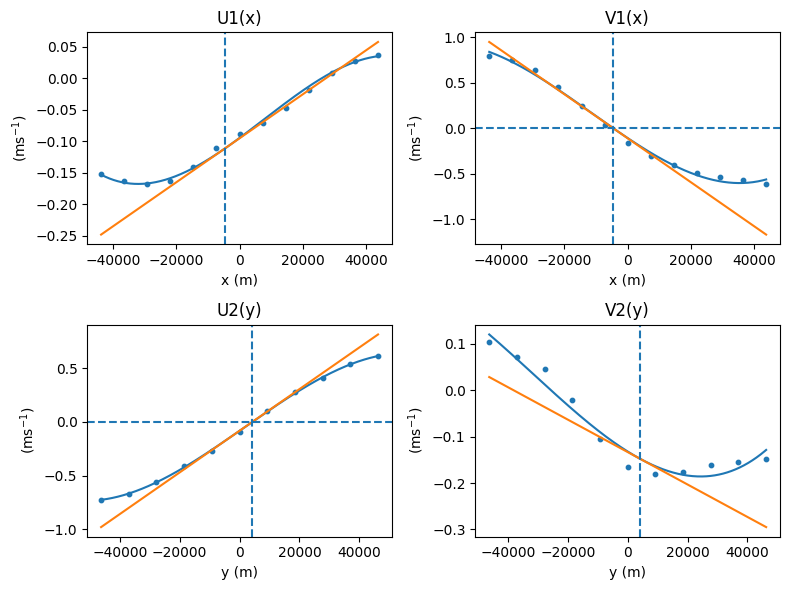

,xc,yc,w,Q,Omega,time,alpha
0,-5144.180387,-800.663483,-0.000040,"[[1.0280107183691718, -0.0930366149255668], [-...",-0.000020,2023-10-19 00:00:00,1.100530
1,-3471.712449,291.427031,-0.000041,"[[0.9684655841855296, -0.09215955330118], [-0....",-0.000020,2023-10-19 23:56:15,1.103998
2,-7757.093422,-5434.898139,-0.000041,"[[0.9247745424860453, -0.11938472356695586], [...",-0.000020,2023-10-21 00:00:00,1.157895
3,-3099.366275,-4604.798140,-0.000042,"[[0.8961236796590435, -0.12741809979781069], [...",-0.000021,2023-10-22 00:00:00,1.189394
4,-628.998343,-4833.042051,-0.000041,"[[0.8196409602129957, -0.0562239781323896], [-...",-0.000020,2023-10-22 23:56:15,1.231577
...,...,...,...,...,...,...,...
96,-251033.941540,167598.532475,-0.000028,"[[1.2672826559193648, 0.029147865851923412], [...",-0.000013,2024-01-23 00:00:00,1.269055
97,-254355.355003,163016.234021,-0.000021,"[[1.6534583204066875, -0.22397375089068175], [...",-0.000009,2024-01-24 00:00:00,1.700543
98,-268077.500792,155429.638075,-0.000018,"[[1.3489182803865105, -0.45042008596121597], [...",-0.000008,2024-01-25 00:00:00,1.625433
99,-261713.865208,165945.084687,-0.000018,"[[1.236949671663108, -0.5068197096948843], [-0...",-0.000008,2024-01-26 00:00:00,1.645235


In [3]:
initial_center = tuple(analysis["initial_center_m"])
xc_pre, yc_pre = initial_center
transect_radius = analysis["transect_half_length_m"]
tracking_stop = "input record exhausted"
rotation_sign = None
max_center_step = analysis["max_center_step_m"]
inner_count_rows = []
rows = []
xyuv_rows = []

X = ds_cop.x.values
Y = ds_cop.y.values

for t, time in enumerate(ds_cop.time.values):
    ut = ds_cop.u.sel(time=time).values
    vt = ds_cop.v.sel(time=time).values

    x1,y1,u1,v1,x2,y2,u2,v2 = doppio_pipeliner(xc_pre, yc_pre, ut.T, vt.T, X.T, Y.T, r=transect_radius)
    inner_details = {}
    xc, yc, w, Q, Omega = doppio(x1,y1,u1,v1,x2,y2,u2,v2, plot=plot_config["diagnostics"] and t == plot_config["diagnostic_step_index"], fit_details=inner_details)

    ok, reason = tracking_acceptance((xc_pre, yc_pre), (xc, yc, w, Q, Omega),
                                     rotation_sign=rotation_sign, max_step=max_center_step)

    if not ok:
        tracking_stop = f"rejected {time}: {reason}; inner status={inner_details.get('status')}"
        break

    if rotation_sign is None:
        rotation_sign = np.sign(w)
    rows.append(dict(xc=xc, yc=yc, w=w, Q=Q, Omega=Omega, time=time))
    xc_pre, yc_pre = xc, yc

    xi = np.concatenate([x1, x2])
    yi = np.concatenate([y1, y2])
    ui = np.concatenate([u1, u2])
    vi = np.concatenate([v1, v2])

    finite = np.isfinite(xi) & np.isfinite(yi) & np.isfinite(ui) & np.isfinite(vi)
    inner_count_rows.append({"time": time, "transect_input_pairs": int(finite.sum()),
                             "unique_transect_positions": len(np.unique(np.column_stack([xi[finite], yi[finite]]), axis=0))})
    xyuv_rows.append(pd.DataFrame({
        "time": time,
        "core": "inner",
        "xi": xi, "yi": yi, "ui": ui, "vi": vi
    }))

df_res = pd.DataFrame(rows, columns=["xc","yc","w","Q","Omega","time"])
if df_res.empty:
    raise RuntimeError("No accepted DOPPIO fits: " + tracking_stop)
df_res["alpha"] = [axis_ratio_from_Q(Q) for Q in df_res["Q"].to_list()]

df_xyuv = pd.concat(xyuv_rows, ignore_index=True) if xyuv_rows else pd.DataFrame(
    columns=["time","core","xi","yi","ui","vi"]
)

df_res


#### Calculate outer-core ESP parameters

,xc,yc,w,Q,Omega,time,alpha,Omega_core,w_core,fit_status,Rc,psi0
0,-5144.180387,-800.663483,-0.000036,"[[1.0280107183691718, -0.0930366149255668], [-...",-0.000018,2023-10-19 00:00:00,1.100530,-0.000020,-0.000040,optimized,84050.313233,63067.165908
1,-3471.712449,291.427031,-0.000036,"[[0.9684655841855296, -0.09215955330118], [-0....",-0.000018,2023-10-19 23:56:15,1.103998,-0.000020,-0.000041,optimized,83628.751707,62598.245289
2,-7757.093422,-5434.898139,-0.000036,"[[0.9247745424860453, -0.11938472356695586], [...",-0.000018,2023-10-21 00:00:00,1.157895,-0.000020,-0.000041,optimized,84719.687205,63222.520829
3,-3099.366275,-4604.798140,-0.000037,"[[0.8961236796590435, -0.12741809979781069], [...",-0.000018,2023-10-22 00:00:00,1.189394,-0.000021,-0.000042,optimized,83101.827821,62913.762345
4,-628.998343,-4833.042051,-0.000037,"[[0.8196409602129957, -0.0562239781323896], [-...",-0.000018,2023-10-22 23:56:15,1.231577,-0.000020,-0.000041,optimized,82764.047683,62456.350446
...,...,...,...,...,...,...,...,...,...,...,...,...
96,-251033.941540,167598.532475,-0.000035,"[[1.2672826559193648, 0.029147865851923412], [...",-0.000017,2024-01-23 00:00:00,1.269055,-0.000013,-0.000028,optimized,62264.800229,33064.980003
97,-254355.355003,163016.234021,-0.000033,"[[1.6534583204066875, -0.22397375089068175], [...",-0.000014,2024-01-24 00:00:00,1.700543,-0.000009,-0.000021,optimized,66254.640325,31794.487101
98,-268077.500792,155429.638075,-0.000029,"[[1.3489182803865105, -0.45042008596121597], [...",-0.000013,2024-01-25 00:00:00,1.625433,-0.000008,-0.000018,optimized,70810.348468,32082.421337
99,-261713.865208,165945.084687,-0.000023,"[[1.236949671663108, -0.5068197096948843], [-0...",-0.000010,2024-01-26 00:00:00,1.645235,-0.000008,-0.000018,optimized,79340.083325,31771.892862


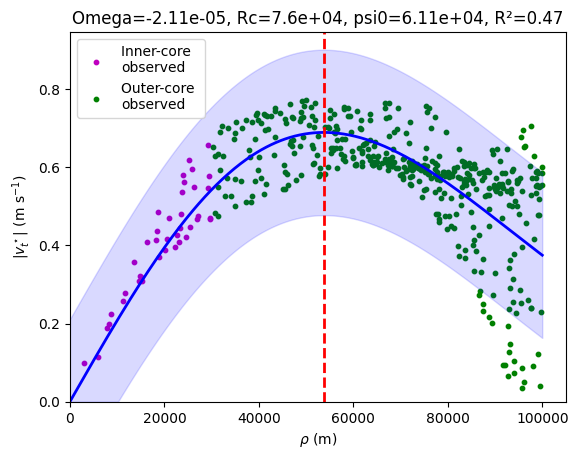

In [4]:
rho_outer = analysis["outer_radius_m"]

xi0 = ds_cop.x.values.ravel()
yi0 = ds_cop.y.values.ravel()

Rc_opts, psi0_opts, Omega_opts = [], [], []
xyuv_rows = []
outer_records = []
outer_count_rows = []

for k, data in df_res.iterrows():
    time = data.time

    ui0 = ds_cop.u.sel(time=time).values.ravel()
    vi0 = ds_cop.v.sel(time=time).values.ravel()

    xc, yc = float(data.xc), float(data.yc)
    Q = np.asarray(data.Q)
    Omega = float(data.Omega)
    q11, q12, q22 = Q[0,0], Q[0,1], Q[1,1]

    dx = xi0 - xc
    dy = yi0 - yc
    rho2 = q11*dx*dx + 2*q12*dx*dy + q22*dy*dy

    outer = rho2 <= rho_outer**2
    xi_o, yi_o = xi0[outer], yi0[outer]
    ui_o, vi_o = ui0[outer], vi0[outer]

    xyuv_rows.append(pd.DataFrame({
        "time": time, "core": "outer",
        "xi": xi_o, "yi": yi_o, "ui": ui_o, "vi": vi_o
    }))

    fit_details = {}
    Rc_opt, psi0_opt, Omega_opt = out_core_param_fit(xi_o, yi_o, ui_o, vi_o, xc, yc, Q, Omega0=Omega, plot=plot_config["diagnostics"] and k == plot_config["diagnostic_step_index"], pred_flag=True, fit_details=fit_details, **outer_fit_kwargs)
    outer_records.append(fit_record(time, fit_details))
    outer_count_rows.append({"time": time, "outer_candidates_finite": int((np.isfinite(xi_o) & np.isfinite(yi_o) & np.isfinite(ui_o) & np.isfinite(vi_o)).sum())})

    Rc_opts.append(Rc_opt); psi0_opts.append(psi0_opt); Omega_opts.append(Omega_opt)

df_xyuv_o = pd.concat(xyuv_rows, ignore_index=True) if xyuv_rows else pd.DataFrame(
    columns=["time","core","xi","yi","ui","vi"]
)

df_xyuv = pd.concat([df_xyuv, df_xyuv_o], ignore_index=True)
df_xyuv = (
    df_xyuv
    .sort_values(by="core", key=lambda s: s.eq("outer"))  # keep inner first
    .drop_duplicates(subset=["time", "xi", "yi", "ui", "vi"], keep="first")
    .reset_index(drop=True)
)

df_res["Omega_core"] = df_res["Omega"]
df_res["w_core"] = df_res["w"]
df_res["fit_status"] = [record["outer_fit_status"] for record in outer_records]
df_res["Rc"] = Rc_opts
df_res["psi0"] = psi0_opts
df_res["Omega"] = Omega_opts
df_res["w"] = [Omega*(Q[0,0] + Q[1,1]) for (Omega,Q) in zip(df_res.Omega, df_res.Q)]
df_res


In [5]:
# find (i,j) indices of sampled data
df = df_xyuv.copy()

xg = ds_cop.x[0, :].values
yg = ds_cop.y[:, 0].values
xi = df["xi"].to_numpy()
yi = df["yi"].to_numpy()
i = np.searchsorted(xg, xi)
i = np.clip(i, 1, len(xg) - 1)
i -= (xi - xg[i - 1] < xg[i] - xi)
j = np.searchsorted(yg, yi)
j = np.clip(j, 1, len(yg) - 1)
j -= (yi - yg[j - 1] < yg[j] - yi)
df["i"] = i
df["j"] = j

df_xyuv = df


In [6]:
# Find R2
R2_vals = []
for _, row in df_res.iterrows():
    df = df_xyuv[df_xyuv.time == row.time]
    xi = df.xi.to_numpy(float)
    yi = df.yi.to_numpy(float)
    u  = df.ui.to_numpy(float)
    v  = df.vi.to_numpy(float)
    uhat, vhat = model_uv_at_xy(xi, yi, row.xc, row.yc, np.asarray(row.Q), row.Omega, row.Rc)
    R2_vals.append(vector_R2(u, v, uhat, vhat))
df_res['R2'] = R2_vals
df_res


,xc,yc,w,Q,Omega,time,alpha,Omega_core,w_core,fit_status,Rc,psi0,R2
0,-5144.180387,-800.663483,-0.000036,"[[1.0280107183691718, -0.0930366149255668], [-...",-0.000018,2023-10-19 00:00:00,1.100530,-0.000020,-0.000040,optimized,84050.313233,63067.165908,0.941088
1,-3471.712449,291.427031,-0.000036,"[[0.9684655841855296, -0.09215955330118], [-0....",-0.000018,2023-10-19 23:56:15,1.103998,-0.000020,-0.000041,optimized,83628.751707,62598.245289,0.953325
2,-7757.093422,-5434.898139,-0.000036,"[[0.9247745424860453, -0.11938472356695586], [...",-0.000018,2023-10-21 00:00:00,1.157895,-0.000020,-0.000041,optimized,84719.687205,63222.520829,0.922006
3,-3099.366275,-4604.798140,-0.000037,"[[0.8961236796590435, -0.12741809979781069], [...",-0.000018,2023-10-22 00:00:00,1.189394,-0.000021,-0.000042,optimized,83101.827821,62913.762345,0.950186
4,-628.998343,-4833.042051,-0.000037,"[[0.8196409602129957, -0.0562239781323896], [-...",-0.000018,2023-10-22 23:56:15,1.231577,-0.000020,-0.000041,optimized,82764.047683,62456.350446,0.954496
...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,-251033.941540,167598.532475,-0.000035,"[[1.2672826559193648, 0.029147865851923412], [...",-0.000017,2024-01-23 00:00:00,1.269055,-0.000013,-0.000028,optimized,62264.800229,33064.980003,0.402878
97,-254355.355003,163016.234021,-0.000033,"[[1.6534583204066875, -0.22397375089068175], [...",-0.000014,2024-01-24 00:00:00,1.700543,-0.000009,-0.000021,optimized,66254.640325,31794.487101,0.468449
98,-268077.500792,155429.638075,-0.000029,"[[1.3489182803865105, -0.45042008596121597], [...",-0.000013,2024-01-25 00:00:00,1.625433,-0.000008,-0.000018,optimized,70810.348468,32082.421337,0.385979
99,-261713.865208,165945.084687,-0.000023,"[[1.236949671663108, -0.5068197096948843], [-0...",-0.000010,2024-01-26 00:00:00,1.645235,-0.000008,-0.000018,optimized,79340.083325,31771.892862,0.452017


In [7]:
# Reconstruct velocity field using ESP parameters
X = ds_cop.x.values
Y = ds_cop.y.values
nt = len(df_res)

U = np.empty((nt, X.shape[0], X.shape[1]))
V = np.empty((nt, X.shape[0], X.shape[1]))

for k in range(nt):
    data = df_res.iloc[k]

    dx = X - data.xc
    dy = Y - data.yc

    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]

    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2
    fac = data.Omega * np.exp(-rho2 / data.Rc**2)

    U[k] = -fac * (q12*dx + q22*dy)
    V[k] =  fac * (q11*dx + q12*dy)

mask = ds_cop.land_mask.values[None, :, :]   # (1, lat, lon)
U = np.where(mask, np.nan, U)
V = np.where(mask, np.nan, V)

ds_model = xr.Dataset(
    data_vars=dict(
        u=(("time","lat","lon"), U),
        v=(("time","lat","lon"), V),
    ),
    coords=dict(
        time=df_res.time.values,
        lat=ds_cop.lat.values,
        lon=ds_cop.lon.values,
        x=(("lat","lon"), X),
        y=(("lat","lon"), Y),
    ),
)


In [8]:
def plot_model(df_res, ds_cop, ds_model, df_xyuv, time=None, spac=1, scale=20,
                xlim=(-410, 200), ylim=(-160, 260), out_thresh=False, plot_data=False):

    if time is None:
        time = ds_model.time.values[0]

    sat = ds_cop.sel(time=time, method="nearest")
    mod = ds_model.sel(time=time, method="nearest")
    data = df_res[df_res.time == time].iloc[0]
    if not np.isfinite([data.Omega, data.Rc]).all() or data.Rc <= 0:
        print("Gaussian figure unavailable at", time, ":", data.get("fit_status", "invalid outer fit"))
        return

    X = sat.x.values / 1e3
    Y = sat.y.values / 1e3

    us, vs = sat.u.values, sat.v.values
    um, vm = mod.u.values, mod.v.values

    sp_s = np.hypot(us, vs)
    sp_m = np.hypot(um, vm)

    dx, dy = sat.x.values - data.xc, sat.y.values - data.yc
    q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]
    rho2 = q11*dx**2 + 2*q12*dx*dy + q22*dy**2

    roi = (X >= xlim[0]) & (X <= xlim[1]) & (Y >= ylim[0]) & (Y <= ylim[1])
    sp_s_roi = np.where(roi, sp_s, np.nan)
    sp_m_roi = np.where(roi, sp_m, np.nan)
    roi_quiv = roi & (rho2 >= analysis["outer_radius_m"]**2)

    vals = np.concatenate([sp_s_roi[roi], sp_m_roi[roi]])
    vmax = np.nanmax(vals)
    levels = np.arange(0, vmax + .05, .05)

    X_rho, Y_rho = np.meshgrid(np.linspace(xlim[0]*1e3, xlim[1]*1e3, 100),
                               np.linspace(ylim[0]*1e3, ylim[1]*1e3, 100))
    dx = X_rho - data.xc
    dy = Y_rho - data.yc
    rho2 = data.Q[0,0]*dx**2 + 2*data.Q[0,1]*dx*dy + data.Q[1,1]*dy**2

    fig, axs = plt.subplots(1, 2, figsize=(15, 8), sharex=True, sharey=True, constrained_layout=True)

    # ----- coloured center path -----
    x_path = df_res.xc.to_numpy() / 1e3
    y_path = df_res.yc.to_numpy() / 1e3
    t_path = pd.to_datetime(df_res.time)
    t_num = mdates.date2num(t_path)

    pts = np.array([x_path, y_path]).T.reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)

    norm_t = Normalize(t_num.min(), t_num.max())
    lc0 = LineCollection(segs, cmap="plasma", norm=norm_t, linewidth=2, zorder=2)
    lc0.set_array(t_num[:-1])

    lc1 = LineCollection(segs, cmap="plasma", norm=norm_t, linewidth=2, zorder=2)
    lc1.set_array(t_num[:-1])

    # ---- Numerical model ----
    h0 = axs[0].contourf(X, Y, sp_s_roi, levels=levels, cmap="Blues_r")

    axs[0].quiver(X[::spac,::spac], Y[::spac,::spac],
                  np.where(roi_quiv[::spac,::spac], us[::spac,::spac], np.nan),
                  np.where(roi_quiv[::spac,::spac], vs[::spac,::spac], np.nan),
                  scale=scale, width=.0015, alpha=.4)

    axs[0].scatter(data.xc/1e3, data.yc/1e3, marker="x", color="r", s=50, zorder=3)
    axs[0].add_collection(lc0)
    axs[0].contour(X_rho/1e3, Y_rho/1e3, rho2, levels=[(data.Rc**2)/2], colors="r", linewidths=2, linestyles='--', zorder=3)

    if plot_data:
        df = df_xyuv[(df_xyuv.time == time) & (df_xyuv.core == 'outer')]

        ni, nj = X.shape
        
        U = np.full((ni, nj), np.nan)
        V = np.full((ni, nj), np.nan)
        
        # fill grid
        U[df["j"], df["i"]] = df["ui"].values
        V[df["j"], df["i"]] = df["vi"].values
        
        axs[0].quiver(
            X[::spac, ::spac],
            Y[::spac, ::spac],
            U[::spac, ::spac],
            V[::spac, ::spac],
            scale=scale,
            width=.0025,
            color='g',
            label='Outer-core data',
            zorder=2
        )
        
        df = df_xyuv[(df_xyuv.time == time) & (df_xyuv.core == 'inner')]
        axs[0].quiver(df.xi/1e3, df.yi/1e3, df.ui, df.vi,
                      scale=scale, width=.0025, color='m', label='Transect/inner-core data', zorder=3)

    axs[0].set_aspect("equal")
    axs[0].legend(loc='lower left')

    # ---- Fitted model ----
    h1 = axs[1].contourf(X, Y, sp_m_roi, levels=levels, cmap="Blues_r")
    axs[1].quiver(X[::spac,::spac], Y[::spac,::spac],
                  np.where(roi[::spac,::spac], um[::spac,::spac], np.nan),
                  np.where(roi[::spac,::spac], vm[::spac,::spac], np.nan),
                  scale=scale, width=.0015, alpha=.5)
    axs[1].scatter(data.xc/1e3, data.yc/1e3, marker="x", color="r", s=50, label='Eddy center', zorder=3)
    axs[1].plot([np.nan, np.nan], [np.nan, np.nan], lw=2, color='r', label='Max tangential\nvelocity', ls='--')
    axs[1].add_collection(lc1)
    axs[1].contour(X_rho/1e3, Y_rho/1e3, rho2, levels=[(data.Rc**2)/2], colors="r", linewidths=2, linestyles='--', zorder=3)

    axs[1].set_aspect("equal")
    axs[1].legend(loc='lower left')

    gap = 20
    for ax in axs:
        ax.set_xlim(xlim[0] + gap, xlim[1] - gap)
        ax.set_ylim(ylim[0] + gap, ylim[1] - gap)
        ax.set_xlabel("x (km)")
    axs[0].set_ylabel("y (km)")

    axs[0].text(-0.05, 1.05, "a)", transform=axs[0].transAxes, fontsize=13, fontweight="bold", va="top", ha="left")
    axs[1].text(-0.05, 1.05, "b)", transform=axs[1].transAxes, fontsize=13, fontweight="bold", va="top", ha="left")

    # speed colourbar
    cbar1 = fig.colorbar(h1, ax=axs, label="Current speed (m s$^{-1}$)", fraction=0.0165, pad=0.02)

    # time colourbar on far right
    cbar2 = fig.colorbar(lc1, ax=axs, fraction=0.0165, pad=0.025)
    cbar2.set_label("Center path time")
    cbar2.ax.yaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))

    plt.show()


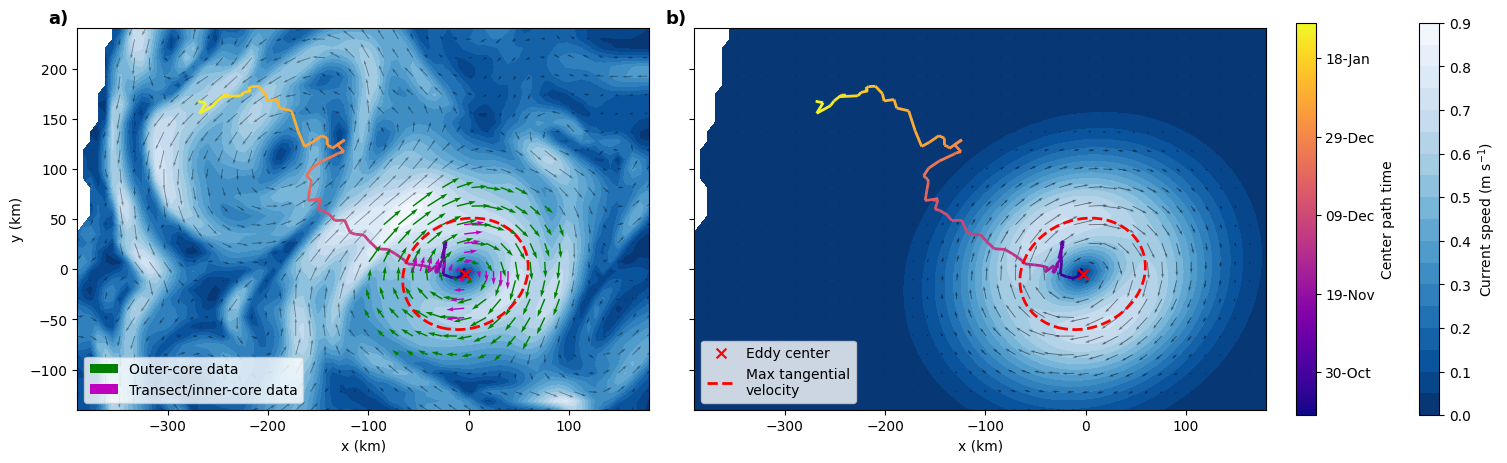

In [9]:
figure_time = select_snapshot_time(df_res.time.values, plot_config["snapshot_utc"], plot_config["snapshot_tolerance_hours"])
plot_model(df_res, ds_cop, ds_model, df_xyuv, time=figure_time, spac=plot_config["quiver_spacing"], scale=plot_config["quiver_scale"],
           xlim=plot_config["x_limits_km"], ylim=plot_config["y_limits_km"],
           out_thresh=False, plot_data=plot_config["plot_data"])


In [10]:
# Results
df_paper = df_res.copy()
df_paper.iloc[::10]


,xc,yc,w,Q,Omega,time,alpha,Omega_core,w_core,fit_status,Rc,psi0,R2
0,-5144.180387,-800.663483,-0.000036,"[[1.0280107183691718, -0.0930366149255668], [-...",-0.000018,2023-10-19 00:00:00,1.100530,-0.000020,-0.000040,optimized,84050.313233,63067.165908,0.941088
10,-25377.577980,-5023.125844,-0.000043,"[[1.1314654368003254, 0.16373431896977003], [0...",-0.000021,2023-10-29 00:00:00,1.217849,-0.000021,-0.000044,optimized,76026.262241,61071.342642,0.952194
20,-24277.256734,20181.693874,-0.000040,"[[1.245624601739496, -0.06684672174911799], [-...",-0.000020,2023-11-08 00:00:00,1.255573,-0.000021,-0.000042,optimized,78540.371163,60204.623136,0.965947
30,-30235.762011,-1614.309561,-0.000035,"[[1.1647732827130535, -0.04550281532754404], [...",-0.000017,2023-11-18 00:00:00,1.171428,-0.000021,-0.000043,optimized,94399.686294,77164.227650,0.815518
40,-51255.062832,4338.439158,-0.000035,"[[1.1051606711228776, -0.05563201332679959], [...",-0.000017,2023-11-28 00:00:00,1.119752,-0.000020,-0.000041,optimized,92514.426297,73532.339085,0.859978
50,-118122.992458,36707.573022,-0.000043,"[[1.1075758287052946, -0.148771172339036], [-0...",-0.000021,2023-12-08 00:00:00,1.190325,-0.000022,-0.000046,optimized,88915.916841,83027.866399,0.774100
60,-159890.317670,69070.130773,-0.000042,"[[1.213919806600551, -0.15244653741072908], [-...",-0.000020,2023-12-17 23:56:15,1.268525,-0.000018,-0.000038,optimized,88249.816207,78883.114196,0.652356
70,-124245.516570,117073.810510,-0.000048,"[[0.5978150649566724, -0.14322194548641856], [...",-0.000021,2023-12-28 00:00:00,1.725264,-0.000016,-0.000036,optimized,79301.311612,64828.822399,0.540178
80,-163486.249907,122364.771942,-0.000030,"[[1.759846182559666, -0.17018330462172124], [-...",-0.000013,2024-01-07 00:00:00,1.783995,-0.000014,-0.000032,optimized,103915.908592,68298.353671,0.770157
90,-216926.643410,177841.742976,-0.000044,"[[0.6678093599508762, -0.0710510564424708], [-...",-0.000020,2024-01-17 00:00:00,1.510980,-0.000015,-0.000033,optimized,64500.126976,41706.299158,0.762215


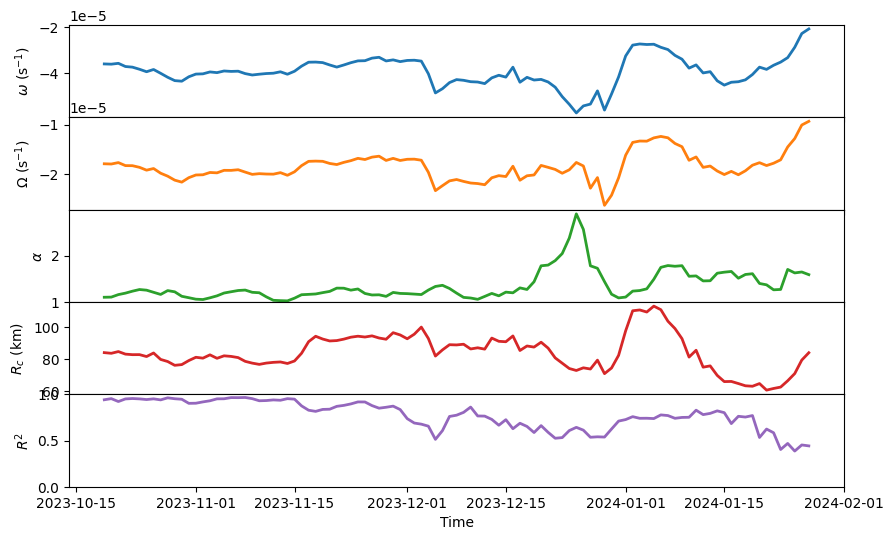

In [11]:
# Time series 
clrs = plt.colormaps['tab10']
fig, axs = plt.subplots(5, 1, figsize=(10,6), sharex=True)
lw = 2

axs[0].plot(df_res.time, df_res.w, color=clrs(0), lw=lw)
axs[0].set_ylabel(r'$\omega$ (s$^{-1}$)')

axs[1].plot(df_res.time, df_res.Omega, color=clrs(1), lw=lw)
axs[1].set_ylabel(r'$\Omega$ (s$^{-1}$)')

axs[2].plot(df_res.time, df_res.alpha, color=clrs(2), lw=lw)
axs[2].set_ylabel(r'$\alpha$')
axs[2].set_ylim(1, None)

axs[3].plot(df_res.time, df_res.Rc/1e3, color=clrs(3), lw=lw)
axs[3].set_ylabel(r'$R_c$ (km)')

axs[4].plot(df_res.time, df_res.R2, color=clrs(4), lw=lw)
axs[4].set_ylabel(r'$R^2$')
axs[4].set_xlabel('Time')
axs[4].set_ylim(0,1)

fig.subplots_adjust(hspace=0)


### Manuscript results summary
Computed from this run. All dates are UTC; final refined parameters are reported.
This notebook demonstrates ESP on real data; idealised experiments are outside its scope.

In [12]:
with capture_summary() as manuscript_text:
    summary_counts = pd.DataFrame(inner_count_rows).merge(pd.DataFrame(outer_count_rows), on="time", how="outer")
    summary_counts = summary_counts.merge(evaluation_counts(df_xyuv), on="time", how="left")
    print_manuscript_summary(
        "DOPPIO — gridded numerical velocities", df_res.assign(source="numerical"),
        {"Available analysis interval": f"{ds_cop.time.values[0]} to {ds_cop.time.values[-1]} UTC",
         "Available timesteps": ds_cop.sizes["time"],
         "Local origin (longitude, latitude)": (theta_mean, phi_mean),
         "Initial centre (m)": initial_center,
         "Orthogonal transect half-length (km)": transect_radius / 1000,
         "Outer elliptical radius limit (km)": rho_outer / 1000,
         "Maximum step from previous accepted centre (km)": max_center_step / 1000,
         "Accepted rotation sign": rotation_sign,
         "Tracking termination": tracking_stop},
        counts=summary_counts, outer_records=outer_records, snapshot_time=figure_time,
        notes=["Transect counts are finite inputs to DOPPIO; polynomial selection occurs inside the estimator.",
               "Velocity R² uses the deduplicated union of inner-transect and outer-region evaluation rows.",
               "Dates are the decoded file timestamps; any model timestamp precision errors remain visible.",
               "The snapshot date above is the actual plotted timestep; check it against the figure caption."],
        input_files=["applications/DOPPIO_gridded_data.ipynb", *config["inputs"].values()], root=REPO_ROOT)

export_directory = export_application_results(
    REPO_ROOT, CONFIG_PATH, config,
    df_res, manuscript_text.getvalue(),
    notebook="applications/DOPPIO_gridded_data.ipynb",
    tables={"observation_counts": summary_counts, "outer_fit_diagnostics": pd.DataFrame(outer_records)},
    run_info={"snapshot_time_utc": figure_time, "tracking_stop": tracking_stop})



MANUSCRIPT RESULTS SUMMARY — DOPPIO — gridded numerical velocities
Current run; compare with the manuscript after any analysis change. All times UTC.

DATA AND SETTINGS
  Available analysis interval: 2023-10-19T00:00:00.000000000 to 2024-01-27T00:00:00.000000000 UTC
  Available timesteps: 101
  Local origin (longitude, latitude): (154.3, -37.9)
  Initial centre (m): (0.0, 0.0)
  Orthogonal transect half-length (km): 50.0
  Outer elliptical radius limit (km): 100.0
  Maximum step from previous accepted centre (km): 100.0
  Accepted rotation sign: -1.0
  Tracking termination: input record exhausted

PLOTTED SNAPSHOT: 2023-10-22T00:00:00.000000000 UTC

MANUSCRIPT-ROUNDED VALUES (final refined Omega; omega = Omega tr(Q))
  numerical, 2023-10-22 00:00:00 UTC: (x0,y0)=(-3.1, -4.6) km; omega=-3.7e-05 s^-1; Omega=-1.8e-05 s^-1; alpha=1.19; Rc=83.1 km; psi0=62913.8 m^2/s; R²_velocity=0.95

NUMERICAL RESULTS (additional precision, not physical measurement accuracy)
   source                time